# `EventCatalogs`: snap → cascade → avalanche

This notebook shows the hierarchical catalog data structure returned by
`crumpling.catalogs.build_catalogs`.

Clustering is unchanged: run the pipeline once, then wrap the
`SimulationResult` into three pandas catalogs linked by parent/child IDs.

| Level | Field | Parent link | Children |
|---|---|---|---|
| snaps | `bundle.snaps` | `cascade_id`, `avalanche_id` | — |
| cascades | `bundle.cascades` | `avalanche_id` | `member_snap_ids` |
| avalanches | `bundle.avalanches` | — | `member_cascade_ids` |

External IDs are **1-based**. Unset parents are pandas `NA` (current detection
assigns every snap and cascade).

In [1]:
from __future__ import annotations

import pathlib
import sys

import matplotlib.pyplot as plt
import pandas as pd


def find_repo_root() -> pathlib.Path:
    here = pathlib.Path.cwd().resolve()
    for base in (here, *here.parents):
        if (base / "pyproject.toml").is_file() and (base / "crumpling").is_dir():
            return base
    raise FileNotFoundError(f"Could not locate the repository above {here}")


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from crumpling import catalogs
from crumpling import config
from crumpling import pipeline

DATA = ROOT / (
    "data/raw/trial32/"
    "N40K-compress-LJ10-T0.001-F0.61-damp4.0_stage1_trial32_dt10-dr400__swaps.txt"
)
CONFIG = ROOT / "configs/trial32/swapstat.params.ini"
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 60)


## 1. Build the data structure

`analyze_file` clusters snaps into cascades and cascades into avalanches.
`build_catalogs` only reshapes that result — it does not re-cluster.

In [2]:
settings = config.load_config(CONFIG)
result = pipeline.analyze_file(DATA, settings)
bundle = catalogs.build_catalogs(result)

print(type(bundle).__name__)
print("source:", bundle.source.name)
print(
    f"snaps={len(bundle.snaps)}  "
    f"cascades={len(bundle.cascades)}  "
    f"avalanches={len(bundle.avalanches)}"
)


EventCatalogs
source: N40K-compress-LJ10-T0.001-F0.61-damp4.0_stage1_trial32_dt10-dr400__swaps.txt
snaps=3242  cascades=892  avalanches=225


## 2. Peek at each catalog

Each level is a time-sorted DataFrame with earthquake-style columns
(`time`, `magnitude`, `dt`, `cumulative_count`, …) plus membership fields.

In [3]:
summary = pd.DataFrame(
    {
        "catalog": ["snaps", "cascades", "avalanches"],
        "n_events": [
            len(bundle.snaps),
            len(bundle.cascades),
            len(bundle.avalanches),
        ],
        "columns": [
            list(bundle.snaps.columns),
            list(bundle.cascades.columns),
            list(bundle.avalanches.columns),
        ],
    }
)
summary


,catalog,n_events,columns
0,snaps,3242,"[event_id, source_number, time, x, y, z, magnitude, surf..."
1,cascades,892,"[event_id, time, time_start, time_end, duration, x, y, z..."
2,avalanches,225,"[event_id, time, time_start, time_end, duration, x, y, z..."


In [4]:
bundle.snaps.head(3)


,event_id,source_number,time,x,y,z,magnitude,surface_area,cascade_id,avalanche_id,dt,log10_dt,cumulative_count
0,1,1,3.183,1084.510,1849.00,0.0,0.0,3.465718e+06,1,1,NaN,NaN,1
1,2,2,4.185,532.185,1838.29,0.0,0.0,3.464880e+06,4,3,1.002,0.000868,2
2,3,3,4.506,666.580,1821.49,0.0,0.0,3.464638e+06,4,3,0.321,-0.493495,3


In [5]:
bundle.cascades.head(3)


,event_id,time,time_start,time_end,duration,x,y,z,n_swaps,magnitude,radius_of_gyration,diameter,simultaneous_count,avalanche_id,dt,log10_dt,cumulative_count,member_snap_ids
0,1,7.4145,3.183,16.290,13.107,1247.346250,1797.762500,0.0,4,0.602060,132.322267,354.535662,4,1,NaN,NaN,1,"(1, 7, 11, 22)"
1,2,15.9750,9.867,21.465,11.598,1691.005000,269.327833,0.0,3,0.477121,184.451972,397.146202,5,2,8.5605,0.932499,2,"(16, 20, 30)"
2,4,20.0460,4.185,32.820,28.635,475.372614,1781.312187,0.0,16,1.204120,322.561170,1223.999513,5,3,4.0710,0.609701,3,"(2, 3, 4, 5, 8, 9, 21, 26, 31, 32, 33, 34, 38, 39, 42, 46)"


In [6]:
bundle.avalanches.head(3)


,event_id,time,time_start,time_end,duration,x,y,z,n_swaps,n_cascades,magnitude,radius_of_gyration,diameter,temporal_gyration,dt,log10_dt,cumulative_count,member_cascade_ids
0,1,7.4145,3.183,16.290,13.107,1247.346250,1797.762500,0.0,4,1,0.602060,132.322267,353.535662,4.790444,NaN,NaN,1,"(1,)"
1,2,15.9750,9.867,21.465,11.598,1691.005000,269.327833,0.0,3,1,0.477121,184.451972,396.146202,4.737104,8.5605,0.932499,2,"(2,)"
2,3,20.0460,4.185,32.820,28.635,475.372614,1781.312187,0.0,16,1,1.204120,322.561170,1222.999513,9.492794,4.0710,0.609701,3,"(4,)"


## 3. Walk the hierarchy upward (snap → cascade → avalanche)

Pick one snap and follow its parent IDs.

In [7]:
snap = bundle.snaps.iloc[100]
cascade = bundle.cascades.set_index("event_id").loc[int(snap["cascade_id"])]
avalanche = bundle.avalanches.set_index("event_id").loc[int(snap["avalanche_id"])]

pd.DataFrame(
    [
        {
            "level": "snap",
            "event_id": int(snap["event_id"]),
            "time": snap["time"],
            "parent": f"cascade {int(snap['cascade_id'])}",
        },
        {
            "level": "cascade",
            "event_id": int(cascade.name),
            "time": cascade["time"],
            "parent": f"avalanche {int(cascade['avalanche_id'])}",
        },
        {
            "level": "avalanche",
            "event_id": int(avalanche.name),
            "time": avalanche["time"],
            "parent": "—",
        },
    ]
)


,level,event_id,time,parent
0,snap,101,84.552,cascade 19
1,cascade,19,84.552,avalanche 17
2,avalanche,17,84.972,—


## 4. Walk the hierarchy downward (avalanche → cascades → snaps)

Choose a multi-cascade avalanche and expand its members.

In [8]:
# Prefer an avalanche that contains several cascades.
av_row = (
    bundle.avalanches.sort_values("n_cascades", ascending=False).iloc[0]
)
av_id = int(av_row["event_id"])
cascade_ids = list(av_row["member_cascade_ids"])

member_cascades = bundle.cascades.set_index("event_id").loc[cascade_ids]
snap_ids = [
    snap_id
    for ids in member_cascades["member_snap_ids"]
    for snap_id in ids
]
member_snaps = bundle.snaps.set_index("event_id").loc[snap_ids]

print(
    f"avalanche {av_id}: "
    f"{len(cascade_ids)} cascades, {len(snap_ids)} snaps, "
    f"duration={av_row['duration']:.4g}"
)
member_cascades[["time", "n_swaps", "magnitude", "avalanche_id", "member_snap_ids"]].head()


avalanche 125: 52 cascades, 297 snaps, duration=622.7


,time,n_swaps,magnitude,avalanche_id,member_snap_ids
event_id,,,,,
506,5986.440,15,1.176091,125,"(1597, 1598, 1599, 1600, 1601, 1602, 1603, 1604, 1605, 1..."
505,6000.933,1,0.000000,125,"(1611,)"
507,6012.711,1,0.000000,125,"(1613,)"
508,6015.717,1,0.000000,125,"(1615,)"
509,6016.545,1,0.000000,125,"(1617,)"


In [9]:
member_snaps[["time", "x", "y", "cascade_id", "avalanche_id"]].head(8)


,time,x,y,cascade_id,avalanche_id
event_id,,,,,
1597,5966.913,1125.925,1786.995,506,125
1598,5972.010,1122.895,1813.975,506,125
1599,5976.015,1109.640,1807.270,506,125
1600,5977.017,1097.905,1800.685,506,125
1601,5977.026,1075.795,1811.940,506,125
1602,5980.587,1135.175,1780.190,506,125
1603,5986.233,1153.660,1777.950,506,125
1604,5986.440,1044.875,1820.740,506,125


## 5. Filter / join patterns

Common queries: all snaps in one cascade, size distribution of cascades inside
an avalanche, and a join that attaches cascade magnitude onto every snap.

In [10]:
cascade_id = int(bundle.cascades.sort_values("n_swaps", ascending=False).iloc[0]["event_id"])
snaps_in_cascade = bundle.snaps.loc[bundle.snaps["cascade_id"] == cascade_id]

print(f"cascade {cascade_id}: {len(snaps_in_cascade)} snaps")
snaps_in_cascade[["event_id", "time", "x", "y", "avalanche_id"]].head()


cascade 426: 41 snaps


,event_id,time,x,y,avalanche_id
1220,1221,4017.726,1380.270,1623.040,114
1221,1222,4021.542,1389.075,1604.370,114
1223,1224,4026.183,1403.005,1592.230,114
1224,1225,4029.693,1393.265,1593.475,114
1225,1226,4035.429,1392.670,1566.820,114


In [11]:
snaps_with_cascade_mag = bundle.snaps.merge(
    bundle.cascades[["event_id", "magnitude", "n_swaps"]].rename(
        columns={
            "event_id": "cascade_id",
            "magnitude": "cascade_magnitude",
            "n_swaps": "cascade_n_swaps",
        }
    ),
    on="cascade_id",
    how="left",
)
snaps_with_cascade_mag[
    ["event_id", "time", "cascade_id", "cascade_n_swaps", "cascade_magnitude", "avalanche_id"]
].head()


,event_id,time,cascade_id,cascade_n_swaps,cascade_magnitude,avalanche_id
0,1,3.183,1,4,0.60206,1
1,2,4.185,4,16,1.20412,3
2,3,4.506,4,16,1.20412,3
3,4,5.274,4,16,1.20412,3
4,5,5.517,4,16,1.20412,3


## 6. Quick visual check

Space–time view of the avalanche expanded above: cascades as larger markers,
member snaps underneath.

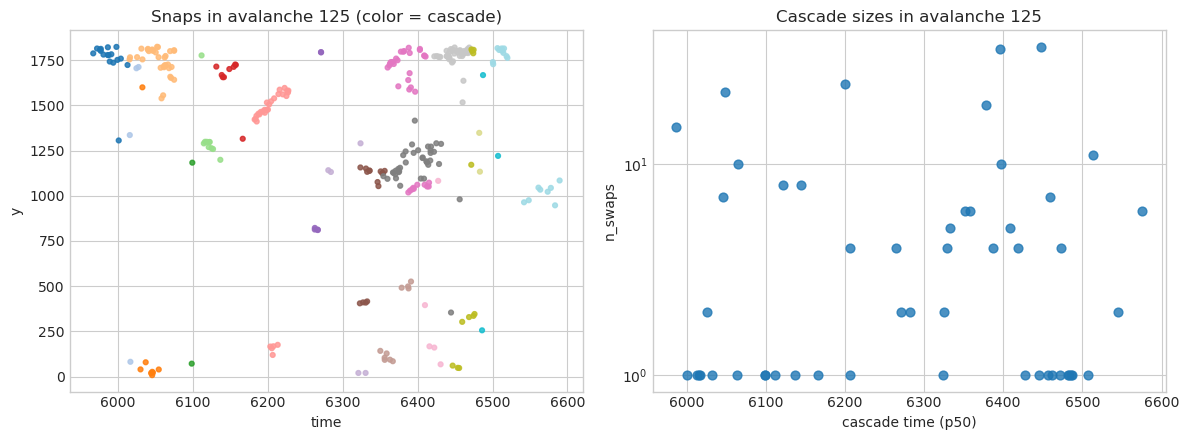

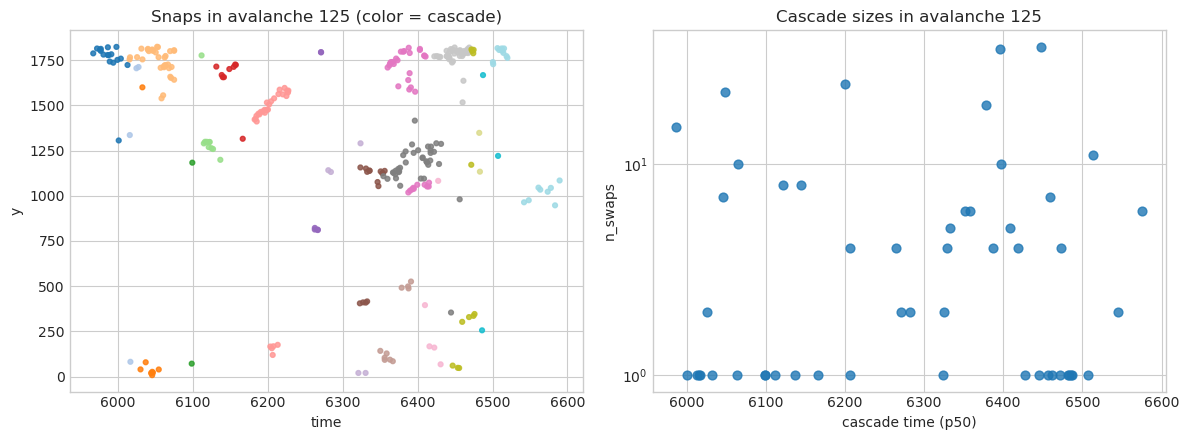

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(
    member_snaps["time"],
    member_snaps["y"],
    c=member_snaps["cascade_id"],
    s=12,
    cmap="tab20",
    alpha=0.85,
)
axes[0].set(
    xlabel="time",
    ylabel="y",
    title=f"Snaps in avalanche {av_id} (color = cascade)",
)

axes[1].scatter(
    member_cascades["time"],
    member_cascades["n_swaps"],
    s=40,
    alpha=0.8,
)
axes[1].set(
    xlabel="cascade time (p50)",
    ylabel="n_swaps",
    title=f"Cascade sizes in avalanche {av_id}",
)
axes[1].set_yscale("log")

fig.tight_layout()
fig


## 7. Minimal recipe

```python
from crumpling import catalogs, config, pipeline

result = pipeline.analyze_file(swap_path, config.load_config(ini_path))
bundle = catalogs.build_catalogs(result)

bundle.snaps          # unit snaps + cascade_id / avalanche_id
bundle.cascades       # + avalanche_id / member_snap_ids
bundle.avalanches     # + member_cascade_ids
```

For deeper analysis plots on these catalogs, see `catalogs_trial32.ipynb`.